# ex003_server_evaluation 結果可視化

サーバーパイプラインにおける話者ID統合・名前推定の精度検証結果を可視化する．

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

OUTPUT_DIR = Path("../../outputs/ex003_server_evaluation")

## 話者ID統合の精度

/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 32020 (\N{CJK UNIFIED IDEOGRAPH-7D14}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 35441 (\N{CJK UNIFIED IDEOGRAPH-8A71}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/1371435309.py:13: UserWarning: Glyph 32773 (\N{CJK UNIFIED ID

/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12473 (\N{KATAKANA LETTER SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12467 (\N{KATAKANA LETTER KO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12450 (\N{KATAKANA LETTER A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35441 (\N{CJK UNIFIED IDEOGRAPH-8A71}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-

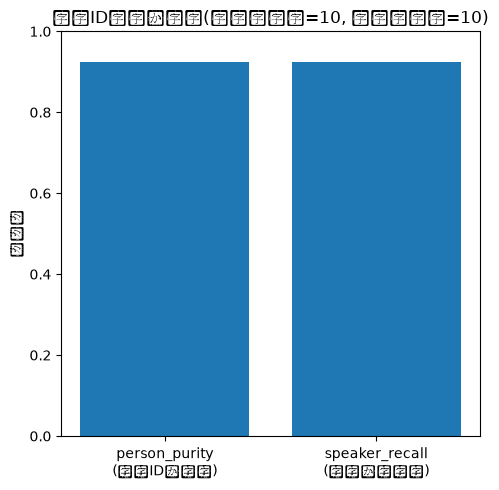

In [2]:
speaker_id_metrics = json.loads((OUTPUT_DIR / "speaker_id" / "metrics.json").read_text(encoding="utf-8"))

fig, ax = plt.subplots(figsize=(5, 5))
labels = ["person_purity\n(人物IDの純度)", "speaker_recall\n(話者の集約率)"]
values = [speaker_id_metrics["person_purity"], speaker_id_metrics["speaker_recall"]]
ax.bar(labels, values)
ax.set_ylim(0, 1.0)
ax.set_ylabel("スコア")
ax.set_title(
    f"話者ID統合の精度(正解話者数={speaker_id_metrics['n_true_speakers']}, "
    f"予測人物数={speaker_id_metrics['n_predicted_persons']})"
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "speaker_id" / "comparison.png")
plt.show()

## 名前推定の精度

/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 35299 (\N{CJK UNIFIED IDEOGRAPH-89E3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 21517 (\N{CJK UNIFIED IDEOGRAPH-540D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3097581/2543739541.py:10: UserWarning: Glyph 21069 (\N{CJK UN

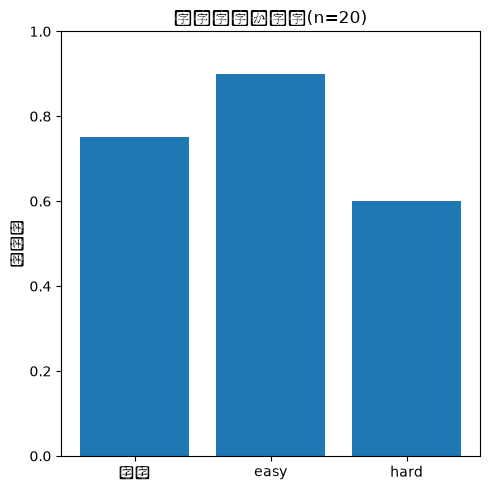

In [3]:
name_metrics = json.loads((OUTPUT_DIR / "name_estimation" / "metrics.json").read_text(encoding="utf-8"))

fig, ax = plt.subplots(figsize=(5, 5))
labels = ["全体"] + list(name_metrics["accuracy_by_difficulty"].keys())
values = [name_metrics["overall_accuracy"]] + list(name_metrics["accuracy_by_difficulty"].values())
ax.bar(labels, values)
ax.set_ylim(0, 1.0)
ax.set_ylabel("正解率")
ax.set_title(f"名前推定の精度(n={name_metrics['n_cases']})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "name_estimation" / "comparison.png")
plt.show()